<div style="background: linear-gradient(135deg, #102a43, #1f7a8c); padding: 28px; border-radius: 14px; color: white;">
<h1 style="margin: 0;">Extended Gradient Descent</h1>
<p style="font-size: 17px; margin-bottom: 0;">A visual walkthrough of multivariable linear regression for car-price prediction.</p>
</div>

## What are we demonstrating?

The extended algorithm learns a linear model with several inputs instead of using mileage alone. It combines numeric features (`km`, `year`, and `engine_size`) with categorical features (`brand` and `model`).

The workflow is:

1. Load and inspect the car dataset.
2. Normalize numeric values and encode categories with one-hot encoding.
3. Add the intercept column and initialize all parameters at zero.
4. Repeatedly calculate predictions, loss, and the gradient.
5. Update the parameters until the loss stops improving.

The model has the form $\hat{y} = X\theta$, where $\theta$ contains one intercept and one coefficient for every prepared feature.

<div style="background: #e8f1f5; border-left: 6px solid #1f7a8c; padding: 14px 18px; border-radius: 8px;">
<b>Goal:</b> estimate the price of a car from its mileage, year, engine size, brand, and model.
</div>

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 15, "axes.labelsize": 11})

DATA_PATH = Path("dataset.csv")
data = pd.read_csv(DATA_PATH)
data.head()

,km,year,engine_size,brand,model,price
0,240000,2008,1.0,Fiat,Punto,3650
1,139800,2010,1.2,Renault,Clio,3800
2,150500,2011,1.4,Fiat,Punto,4400
3,185530,2009,1.6,Volkswagen,Golf,4450
4,176000,2012,1.4,Fiat,Palio,5250


## 1. Explore the training data

In [3]:
numeric_summary = data[["km", "year", "engine_size", "price"]].describe().T
numeric_summary.style.format({"mean": "{:,.1f}", "std": "{:,.1f}", "min": "{:,.1f}", "max": "{:,.1f}"}).background_gradient(cmap="GnBu")

,count,mean,std,min,25%,50%,75%,max
km,24.000000,"101,066.2","52,674.2","22,899.0",65020.500000,83014.500000,140975.000000,"240,000.0"
year,24.000000,"2,014.3",3.0,"2,008.0",2012.750000,2015.000000,2017.000000,"2,018.0"
engine_size,24.000000,1.3,0.2,1.0,1.000000,1.400000,1.600000,1.6
price,24.000000,"6,331.8","1,319.7","3,650.0",5687.500000,6495.000000,7115.000000,"8,290.0"


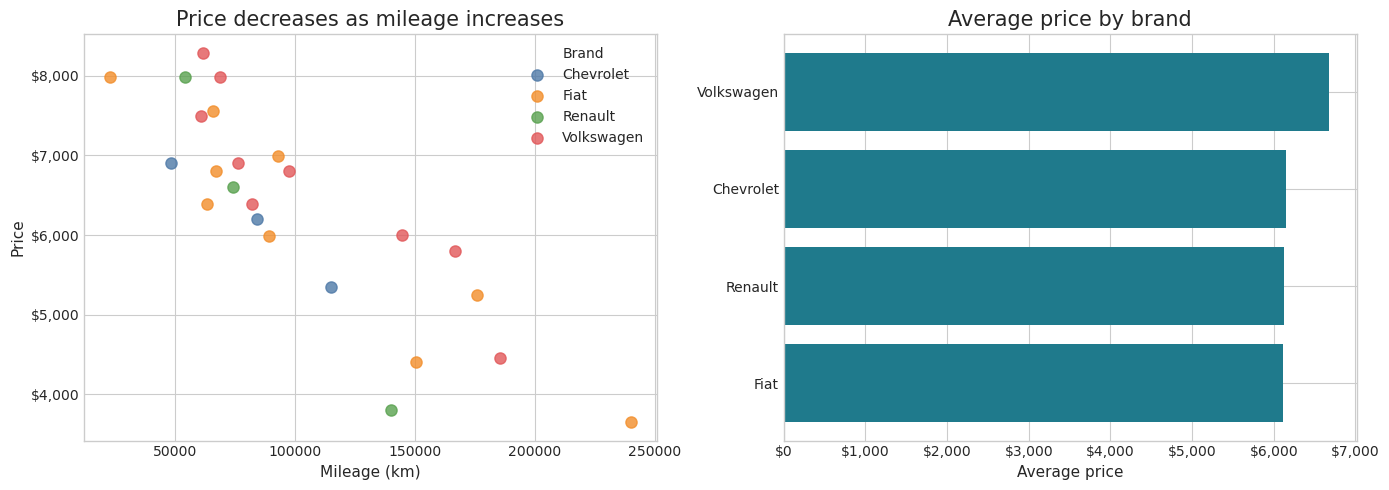

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"Fiat": "#f28e2b", "Chevrolet": "#4e79a7", "Renault": "#59a14f", "Volkswagen": "#e15759"}
for brand, group in data.groupby("brand"):
    axes[0].scatter(group["km"], group["price"], s=65, alpha=0.8, label=brand, color=colors.get(brand))
axes[0].set_title("Price decreases as mileage increases")
axes[0].set_xlabel("Mileage (km)")
axes[0].set_ylabel("Price")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend(title="Brand")

brand_prices = data.groupby("brand", as_index=False)["price"].mean().sort_values("price")
axes[1].barh(brand_prices["brand"], brand_prices["price"], color="#1f7a8c")
axes[1].set_title("Average price by brand")
axes[1].set_xlabel("Average price")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.tight_layout()
plt.show()

## 2. Prepare the feature matrix

Gradient descent works with numbers. Numeric columns are standardized so their scales are comparable, while categorical columns become binary indicator columns. The first category is omitted as the reference category.

In [5]:
numeric_columns = ["km", "year", "engine_size"]
categorical_columns = ["brand", "model"]

scaled_numeric = data[numeric_columns].astype(float).copy()
normalization = {}
for column in numeric_columns:
    mean = scaled_numeric[column].mean()
    std = scaled_numeric[column].std()
    normalization[column] = (mean, std)
    scaled_numeric[column] = (scaled_numeric[column] - mean) / std

encoded_categories = pd.get_dummies(data[categorical_columns], drop_first=True, dtype=float)
features = pd.concat([scaled_numeric, encoded_categories], axis=1)
X = np.column_stack([np.ones(len(features)), features.to_numpy(dtype=float)])
y = data["price"].to_numpy(dtype=float)
feature_names = ["intercept"] + list(features.columns)

print(f"Rows: {X.shape[0]}")
print(f"Features including intercept: {X.shape[1]}")
print("Feature order:")
print(feature_names)

Rows: 24
Features including intercept: 12
Feature order:
['intercept', 'km', 'year', 'engine_size', 'brand_Fiat', 'brand_Renault', 'brand_Volkswagen', 'model_Clio', 'model_Golf', 'model_Palio', 'model_Polo', 'model_Punto']


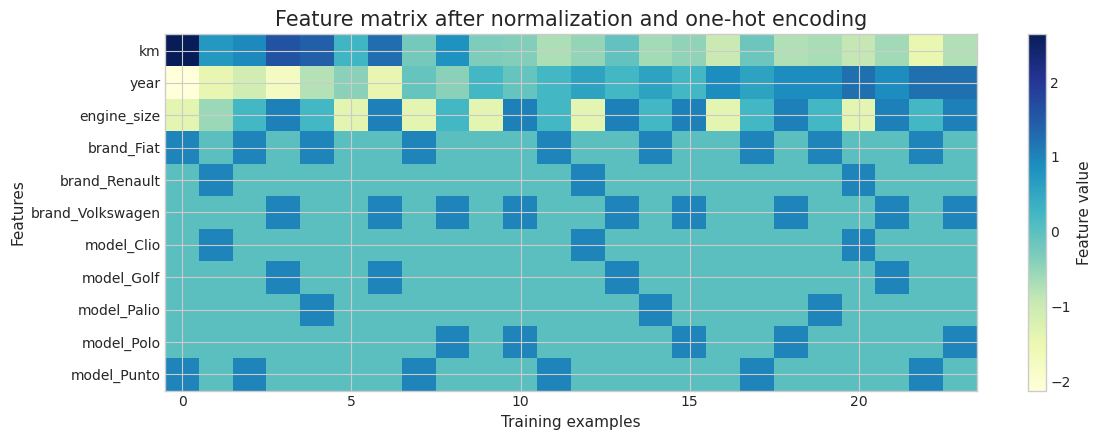

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
image = ax.imshow(X[:, 1:].T, aspect="auto", cmap="YlGnBu")
ax.set_title("Feature matrix after normalization and one-hot encoding")
ax.set_xlabel("Training examples")
ax.set_ylabel("Features")
ax.set_yticks(range(len(feature_names) - 1), feature_names[1:])
fig.colorbar(image, ax=ax, label="Feature value")
plt.tight_layout()
plt.show()

## 3. See one gradient-descent step

At each step, the model compares predictions with real prices. The gradient tells us how each parameter should move to reduce the mean squared error (MSE).

In [7]:
def predict(X, parameters):
    return X @ parameters

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

learning_rate = 0.01
parameters = np.zeros(X.shape[1])
predictions_before = predict(X, parameters)
gradient = 2 * (X.T @ (predictions_before - y)) / len(X)
parameters_after = parameters - learning_rate * gradient
predictions_after = predict(X, parameters_after)

step_table = pd.DataFrame({
    "stage": ["Before update", "After one update"],
    "MSE": [mse(y, predictions_before), mse(y, predictions_after)],
})
step_table.style.format({"MSE": "{:,.0f}"}).background_gradient(cmap="YlOrRd_r", subset=["MSE"])

,stage,MSE
0,Before update,"41,761,039"
1,After one update,"39,335,657"


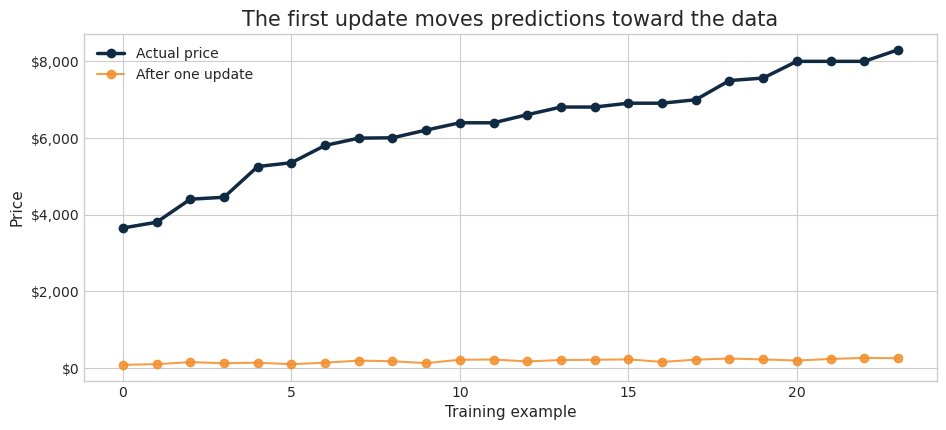

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
comparison = pd.DataFrame({"Actual price": y, "Before update": predictions_before, "After one update": predictions_after})
ax.plot(comparison["Actual price"].to_numpy(), marker="o", linewidth=2.5, label="Actual price", color="#102a43")
ax.plot(comparison["After one update"].to_numpy(), marker="o", alpha=0.85, label="After one update", color="#f28e2b")
ax.set_title("The first update moves predictions toward the data")
ax.set_xlabel("Training example")
ax.set_ylabel("Price")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend()
plt.show()

## 4. Train the complete model

The loop below mirrors the core logic of `train.py`: calculate the gradient, update every parameter, and record the loss after each epoch.

In [9]:
parameters = np.zeros(X.shape[1])
learning_rate = 0.01
epochs = 2500
loss_history = []

for epoch in range(epochs):
    predictions = predict(X, parameters)
    error = predictions - y
    gradient = 2 * (X.T @ error) / len(X)
    parameters -= learning_rate * gradient
    loss_history.append(mse(y, predict(X, parameters)))

final_predictions = predict(X, parameters)
print(f"Training finished after {epochs:,} epochs")
print(f"Final MSE:  {loss_history[-1]:,.2f}")
print(f"Final RMSE: {np.sqrt(loss_history[-1]):,.2f}")

Training finished after 2,500 epochs
Final MSE:  76,191.75
Final RMSE: 276.03


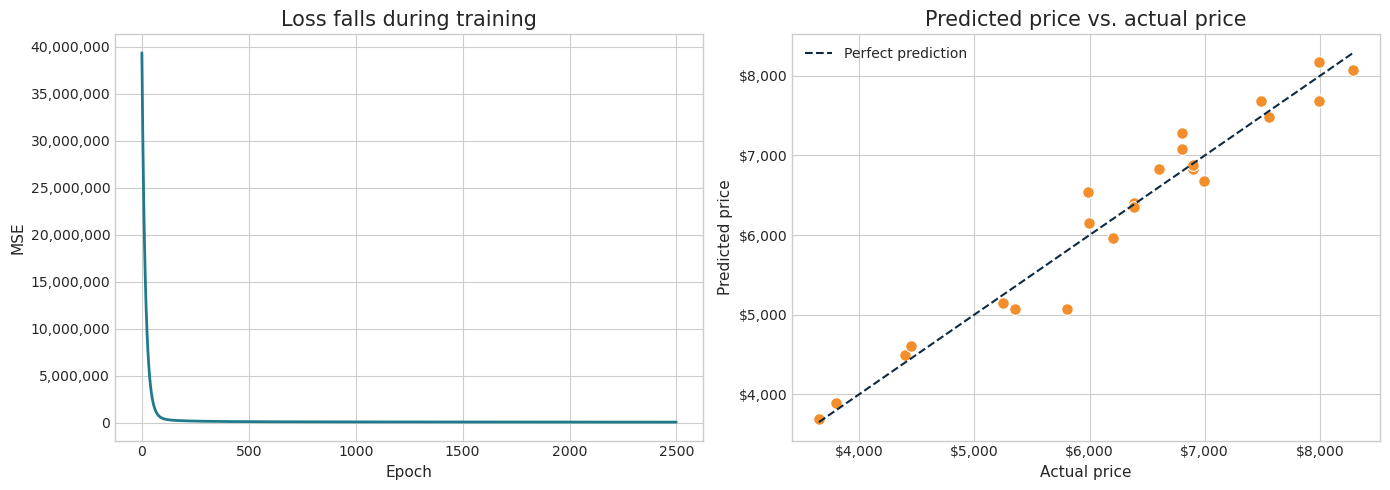

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(loss_history, color="#1f7a8c", linewidth=2)
axes[0].set_title("Loss falls during training")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

axes[1].scatter(y, final_predictions, s=70, color="#f28e2b", edgecolor="white", linewidth=0.8)
line_min, line_max = y.min(), y.max()
axes[1].plot([line_min, line_max], [line_min, line_max], linestyle="--", color="#102a43", label="Perfect prediction")
axes[1].set_title("Predicted price vs. actual price")
axes[1].set_xlabel("Actual price")
axes[1].set_ylabel("Predicted price")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Interpret the learned parameters

The intercept is the baseline prediction. Numeric coefficients describe the effect of a one-standard-deviation change, while categorical coefficients describe the change relative to the omitted reference category.

In [11]:
parameter_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": parameters,
    "absolute_impact": np.abs(parameters),
}).sort_values("absolute_impact", ascending=False)

parameter_table.style.format({"coefficient": "${:,.2f}", "absolute_impact": "${:,.2f}"}).background_gradient(cmap="RdYlGn", subset=["coefficient"])

,feature,coefficient,absolute_impact
0,intercept,"$5,078.11","$5,078.11"
6,brand_Volkswagen,"$1,398.93","$1,398.93"
2,year,"$1,204.92","$1,204.92"
8,model_Golf,$959.64,$959.64
4,brand_Fiat,$774.07,$774.07
9,model_Palio,$550.70,$550.70
10,model_Polo,$439.29,$439.29
3,engine_size,$-409.76,$409.76
11,model_Punto,$223.37,$223.37
7,model_Clio,$219.94,$219.94


## 6. Make a prediction for a new car

In [12]:
def prepare_new_car(km, year, engine_size, brand, model):
    row = {"km": km, "year": year, "engine_size": engine_size, "brand": brand, "model": model}
    new_car = pd.DataFrame([row])
    normalized = new_car[numeric_columns].astype(float).copy()
    for column, (mean, std) in normalization.items():
        normalized[column] = (normalized[column] - mean) / std
    categories = pd.get_dummies(pd.concat([data[categorical_columns], new_car[categorical_columns]]), drop_first=True, dtype=float).iloc[[-1]]
    prepared = pd.concat([normalized, categories], axis=1).reindex(columns=features.columns, fill_value=0)
    return np.column_stack([np.ones(1), prepared.to_numpy(dtype=float)])

new_car = {"km": 90000, "year": 2015, "engine_size": 1.4, "brand": "Fiat", "model": "Palio"}
new_features = prepare_new_car(**new_car)
estimated_price = predict(new_features, parameters)[0]

print("New car:")
for key, value in new_car.items():
    print(f"  {key}: {value}")
print(f"\nEstimated price: ${estimated_price:,.2f}")

New car:
  km: 90000
  year: 2015
  engine_size: 1.4
  brand: Fiat
  model: Palio

Estimated price: $6,606.83


<div style="background: #102a43; padding: 20px; border-radius: 12px; color: white;">
<h2 style="margin-top: 0;">Takeaways</h2>
<ul>
<li>More than one feature can contribute to the same prediction.</li>
<li>Normalization keeps numeric features on comparable scales.</li>
<li>One-hot encoding lets a linear model use categorical information.</li>
<li>Gradient descent learns all coefficients by repeatedly reducing the MSE.</li>
</ul>
</div>